# 04 Selection (LLM filter on the B3 list)

**What this does.** For each target, an LLM reads the target's B3 comp list (names, websites, Sonnet facets and
Fiona's sub-sector; no ranks, similarity, labels or figures) and answers good (1) or bad (0) for every comp, with a
one-sentence reason. One call per target. The kept comps are the B3 + LLM filter route; B3 alone is the other.
This step chooses comps; judges (07) only evaluate.

**Current run (2026-11-18):** Claude Sonnet 5.5 through the Claude Code CLI on the Claude subscription (no API
key), prompt `2026-11-04a` (company size left out), on the current list "Sonnet + Fiona sub-sector": 373 targets,
2,538 pairs.

**Saved outputs:** `outputs-local/v1a/04_selection/`. Each call's prompt and raw answer are kept under `runs/`.

**Changelog**
- 2026-11-18: created. First selector run on the current list (until now only the 11-04 runs on the Haiku-facet
  list existed; they stay in the v1 record and are reproduced below as a check).
- 2026-11-19: section 3.5 ported from `v1/notebooks/comps_and_valuation.ipynb` section 8 (facet separation, lift and
  heatmaps) on the current B3 facet scores and the current selector; F9 and the shared-"none" view stay in v1.


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "v1a" / "current.toml").exists())
sys.path.insert(0, str(ROOT / "v1a" / "common"))
import paths, nbtools as nb
paths.setup()
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)
cur = paths.current()
checks = nb.Checks()

## 1. Current setting (`v1a/current.toml`)

In [2]:
pd.Series(cur["selection"])

route                                                                                       cosine_then_llm
model                                                                                     claude-sonnet-5-5
prompt_version                                                                                  2026-11-04a
backend                                                                                          claude-cli
candidates                                               outputs-local/v1a/03_retrieval/selector_candidates
judgments         outputs-local/v1a/04_selection/b3_selector_candidates_2026-11-04a_claude-cli_claude-so...
dtype: object

## 2. Inputs

In [3]:
run_dir = paths.path(cur["selection"]["judgments"]).parent.parent
nb.inputs([cur["retrieval"]["candidates"] + "/candidates.csv", cur["selection"]["judgments"]])

,input,rows,sha256,status
0,outputs-local/v1a/03_retrieval/selector_candidates/candidates.csv,3730,1544b96bfc27,matches seed
1,outputs-local/v1a/04_selection/b3_selector_candidates_2026-11-04a_claude-cli_claude-so...,2538,dec35ac48af2,new in v1a


## 3. Results

### 3.1 Coverage and keep rate

In [4]:
j = pd.read_csv(paths.path(cur["selection"]["judgments"]), dtype={"target": str, "comp": str})
cand = pd.read_csv(paths.path(cur["retrieval"]["candidates"]) / "candidates.csv", dtype={"target": str, "comp": str})
sel = cand[cand["selected"]]
print(f"{j['target'].nunique()} targets answered, {len(j)} pairs; model {j['model'].unique().tolist()}, prompt {j['prompt_version'].unique().tolist()}")
kept = j.groupby("target")["score"].sum()
pd.Series({"pairs kept (good)": int(j["score"].sum()), "pairs dropped (bad)": int((j["score"] == 0).sum()),
           "keep rate": round(j["score"].mean(), 3), "targets with no comp kept": int((kept == 0).sum()),
           "targets with 3+ comps kept": int((kept >= 3).sum())}).to_frame("value")

373 targets answered, 2538 pairs; model ['claude-sonnet-5-5'], prompt ['2026-11-04a']


,value
pairs kept (good),507.0
pairs dropped (bad),2031.0
keep rate,0.2
targets with no comp kept,108.0
targets with 3+ comps kept,64.0


In [5]:
pd.DataFrame({"comps kept": kept.value_counts().sort_index()}).T

score,0,1,2,3,4,5,6,7
comps kept,108,127,74,39,13,10,1,1


### 3.2 Keep rate by B3 rank and by how the comp entered the list

In [6]:
m = j.merge(sel[["target", "comp", "mutual", "topped_up"]], on=["target", "comp"], how="left")
display(m.groupby("rank")["score"].agg(["count", "mean"]).rename(columns={"count": "pairs", "mean": "keep rate"}).round(3).T)
m.assign(entry=m["topped_up"].map({True: "topped up", False: "mutual top 10"})).groupby("entry")["score"].agg(["count", "mean"]).round(3)

rank,1,2,3,4,5,6,7,8,9,10
pairs,367.000,358.000,328.000,290.000,260.000,242.000,215.000,174.000,165.000,139.000
keep rate,0.638,0.349,0.207,0.141,0.077,0.037,0.014,0.017,0.012,0.014


,count,mean
entry,,
mutual top 10,2492,0.203
topped up,46,0.022


### 3.3 Examples

In [7]:
for t in ["PCTY", "WEN", "THR"]:
    print(t); display(j[j["target_ticker"] == t][["rank", "comp_ticker", "score", "reason"]].sort_values("rank"))

PCTY


,rank,comp_ticker,score,reason
778,1,ASUR,1,"Cloud payroll, HR, time and talent software with tax filing and client-fund interest, ..."
779,2,PAYC,1,Single-platform cloud HCM and payroll subscription software sold directly to mid-sized...
780,3,ADP,1,"Cloud payroll and HCM software with tax filing and client-fund interest, selling to mi..."
781,4,ALIT,0,Outsourced benefits administration and consulting for large employers; services-heavy ...
782,5,BBSI,0,"Regional PEO and staffing business earning co-employment fees and workers' comp, not s..."
783,7,INTU,0,Mostly consumer tax and small-business accounting software; payroll is a minor line wi...
784,10,BLKB,0,"Cloud software for nonprofits and schools (fundraising, school management), not payrol..."


WEN


,rank,comp_ticker,score,reason
576,1,BROS,1,"Drive-thru quick-service chain mixing franchise royalties and company-operated units, ..."
577,2,TXRH,0,Company-operated full-service casual dining steakhouses; different dining format and c...
578,3,STKS,0,"Upscale full-service restaurants, bars and hotel management; different format, custome..."
579,4,HQI,0,Franchised temporary staffing sold to businesses; shares franchise royalties but serve...
580,5,PLNT,0,Franchised budget gyms earning membership and equipment revenue; similar franchise mod...
581,6,BDL,0,Casual full-service sports bar restaurants plus liquor retail in South Florida; differ...
582,7,LW,0,"Manufacturer of frozen potato products sold B2B; a supplier to quick-service chains, n..."


THR


,rank,comp_ticker,score,reason
18,1,FLS,0,"Pumps, valves and seals with aftermarket service; same end customers but different flo..."
19,2,PPIH,1,"Makes heat tracing and pre-insulated piping for oil and gas and industrial projects, w..."
20,3,SPXC,0,"HVAC cooling towers, boilers and locators; mostly building HVAC and detection, only pa..."
21,4,POWL,0,Custom switchgear and power control rooms; similar project model and customers but dif...
22,5,CR,0,"Aerospace sensors plus valves and pumps; no heat tracing or heating systems, so a diff..."
23,6,IESC,0,Mainly electrical contracting for data centers and homebuilders; heating products are ...
24,8,ESAB,0,Welding and cutting equipment and consumables; different products and distribution-dri...
25,9,CGEH,0,Microturbine power generation and rentals; different product and economics from indust...
26,10,MSA,0,Personal safety and gas detection equipment; shares industrial customers but not heati...


### 3.4 Against Barbara's 293 reviewed pairs

Her 0/1/2 grades (rounds 2-3, old form) on the same list. One reviewer, not ground truth; the agent-ranking review
is pending. Read from the seeded review table; it moves to the `dev_293` cohort when 06 is ported.

In [8]:
labels = pd.read_csv(paths.out("06_labels") / "barbara_293" / "review" / "pairs.csv", dtype={"target_id": str, "comp_id": str})
lab = labels.merge(j, left_on=["target_id", "comp_id"], right_on=["target", "comp"], how="left")
print(f"{lab['score'].notna().sum()} of {len(labels)} reviewed pairs have a selector answer")
ct = pd.crosstab(lab["score_barbara"], lab["score"].map({1: "kept", 0: "dropped"}), margins=True)
display(ct)
lab.groupby("score_barbara")["score"].mean().round(3).rename("keep rate").to_frame().T

293 of 293 reviewed pairs have a selector answer


score,dropped,kept,All
score_barbara,,,
0,88,3,91
1,136,42,178
2,0,24,24
All,224,69,293


score_barbara,0,1,2
keep rate,0.033,0.236,1.0


### 3.5 Which facets drive the B3 score, against the selector's verdicts

From `v1/notebooks/comps_and_valuation.ipynb` section 8 (Michael, 10-27), ported on the current inputs: B3's twelve
per-facet scores (0.5 embedding + 0.5 TF-IDF, Sonnet facets plus Fiona's sub-sector) instead of v0's equal-weight
cosines, and the current Sonnet selector's keep/drop on the 2,538 B3 pairs instead of the Haiku judge on z >= 2
candidates. Left in v1: company size (F9) embedded for comparison (out of the similarity since 11-03) and the
shared-"none" correction (B3 treats "none" as missing). Three views:

1. **Separation (AUC).** How well each facet's score alone ranks the comps the selector kept above those it dropped.
   0.5 is chance; the line is a 95% interval from resampling targets. The dashed line is the combined B3 similarity.
2. **Lift of the top 10.** The average score of a target's ten closest comps minus that of a random training pair,
   per facet, each on its own baseline.
3. **Heatmaps for the golden-set targets (PCTY, WEN).** Every comp in the B3 top 10 against every facet, with the
   selector's verdict.

Read these as what moves the score, not what makes a comp good: the facets overlap, and the labels are the LLM's,
which reads the same facet text. The X-learner in `09_analysis` (Method C) gives the adjusted version of view 1.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import facets as fc
import method1_candidates as mc

INK, INK2, GRID, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#eb6834"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2})
GOLDEN = ["PCTY", "WEN"]
RUN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
FACET_OUT = paths.out("04_selection") / "facet_contribution" / RUN    # copies; the results live in this notebook
FACET_OUT.mkdir(parents=True, exist_ok=True)

# v1a: B3's per-facet scores of the current variant (v1: v0's per-facet cosines plus an embedded F9)
universe = pd.read_csv(paths.path(cur["universe"]["universe"]), dtype=str)
info = universe.set_index("IQ_COMPANY_ID")
split = pd.read_csv(paths.path(cur["universe"]["split"]), dtype=str)
training = split.loc[split["sample"] == "training", "IQ_COMPANY_ID"].tolist()
ids = universe["IQ_COMPANY_ID"].tolist()
per_facet_all, _, _ = mc.per_facet(ids, cur)
FACETS = list(per_facet_all)
LABEL = {n: f"{fc.FACET_ID[n]} {n.replace('_', ' ')}" if n in fc.FACET_ID else "sub-sector (Fiona)" for n in FACETS}
ranking = pd.read_csv(paths.path(cur["retrieval"]["candidates"]) / "ranking.csv.gz", dtype={"target": str, "comp": str})
pos = {x: i for i, x in enumerate(ids)}
tr = np.array([pos[x] for x in training])

# baseline: each facet's score over every training pair (target != comp)
offdiag = ~np.eye(len(tr), dtype=bool)
base = {}
for n in FACETS:
    C = per_facet_all[n][np.ix_(tr, tr)][offdiag]
    C = C[~np.isnan(C)]
    base[n] = (C.mean(), C.std())
baseline = pd.DataFrame(base, index=["mean", "sd"]).T


def pair_facets(df):
    ti, ci = df["target"].map(pos).to_numpy(), df["comp"].map(pos).to_numpy()
    return pd.DataFrame({n: per_facet_all[n][ti, ci] for n in FACETS}, index=df.index)


def auc(x, y):
    m = ~np.isnan(x)
    x, y = x[m], y[m]
    n1, n0 = (y == 1).sum(), (y == 0).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(x).rank().to_numpy()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


# 1. separation: the selector's verdicts on the B3 list, kept (1) vs dropped (0)
jp = j.reset_index(drop=True)
jf = pair_facets(jp).assign(combined=jp["similarity"].to_numpy())
y = jp["score"].astype(int).to_numpy()
cols = FACETS + ["combined"]
point = {c: auc(jf[c].to_numpy(), y) for c in cols}
groups = {t: g.index.to_numpy() for t, g in jp.groupby("target")}
rng = np.random.default_rng(2026)                    # v1: the split's seed (sp.SEED = 2026)
boot = {c: [] for c in cols}
tlist = list(groups)
for _ in range(300):
    idx = np.concatenate([groups[t] for t in rng.choice(tlist, len(tlist))])
    for c in cols:
        boot[c].append(auc(jf[c].to_numpy()[idx], y[idx]))
separation = pd.DataFrame({"auc": point,
                           "ci_low": {c: np.nanpercentile(boot[c], 2.5) for c in cols},
                           "ci_high": {c: np.nanpercentile(boot[c], 97.5) for c in cols}})

# 2. lift of each target's top-10 comps (B3 one-way top 10) over a random training pair
top10 = ranking[ranking["in_top_k"]]
lift = (pair_facets(top10).mean() - baseline["mean"]).rename("score_lift").to_frame()
lift["lift_in_sd"] = lift["score_lift"] / baseline["sd"]

summary = separation.drop(index="combined").join(lift).rename_axis("facet")
summary.insert(0, "label", summary.index.map(LABEL))
summary.round(3).to_csv(FACET_OUT / "facet_summary.csv")
print(f"{len(jp)} judged pairs from {len(groups)} targets ({int(y.sum())} kept); "
      f"combined B3 similarity AUC {point['combined']:.3f}")
display(summary.sort_values("auc", ascending=False).round(3))


2538 judged pairs from 373 targets (507 kept); combined B3 similarity AUC 0.899


,label,auc,ci_low,ci_high,score_lift,lift_in_sd
facet,,,,,,
primary_products,F2 primary products,0.834,0.805,0.868,0.197,2.446
offering_description,F1 offering description,0.827,0.800,0.854,0.168,2.410
Fiona sub-sector,sub-sector (Fiona),0.808,0.781,0.836,0.181,2.581
revenue_model,F6 revenue model,0.808,0.780,0.830,0.190,2.135
value_chain_position,F7 value chain position,0.799,0.769,0.829,0.194,2.251
primary_services,F3 primary services,0.781,0.752,0.813,0.204,2.377
specialization,F10 specialization,0.756,0.726,0.788,0.164,2.013
regulatory_exposure,F12 regulatory exposure,0.756,0.726,0.780,0.232,2.568
end_markets,F5 end markets,0.747,0.714,0.778,0.201,1.937


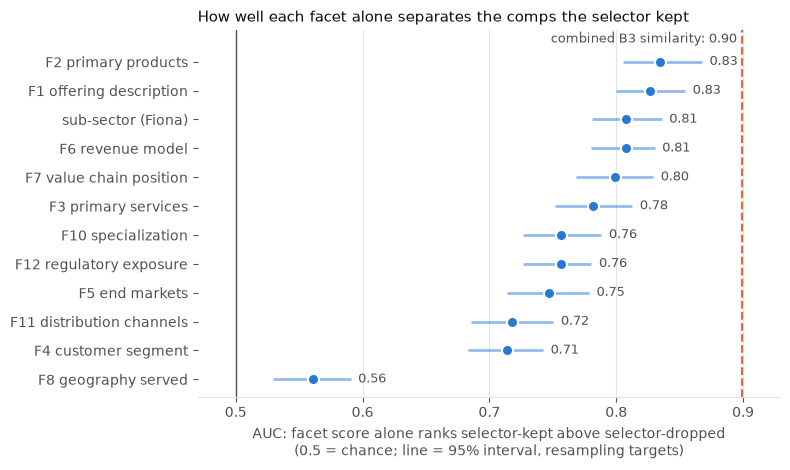

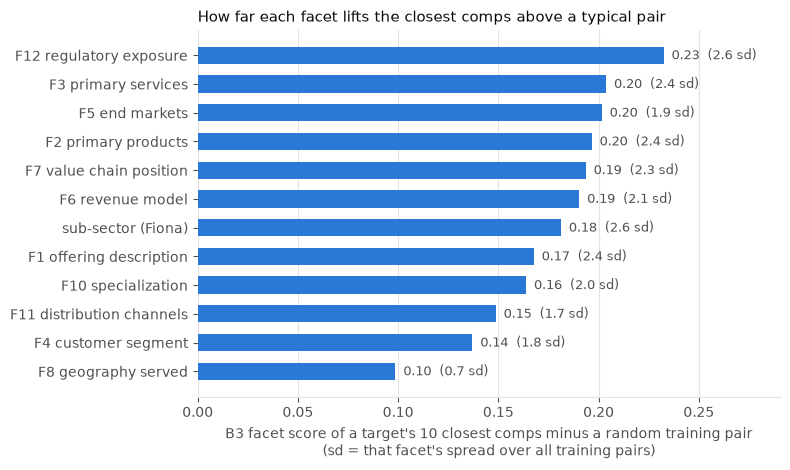

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
d = summary.sort_values("auc")
yy = np.arange(len(d))
ax.hlines(yy, d["ci_low"], d["ci_high"], color=BLUE, lw=2, alpha=0.5)
ax.plot(d["auc"], yy, "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.axvline(0.5, color=INK2, lw=1)
ax.axvline(point["combined"], color=ORANGE, lw=1.5, ls="--")
ax.text(point["combined"] - 0.004, len(d) - 0.2, f"combined B3 similarity: {point['combined']:.2f}", color=INK2, ha="right", va="center", fontsize=9)
ax.set_ylim(-0.6, len(d) + 0.1)
ax.set_xlim(min(0.47, d["ci_low"].min() - 0.02), max(0.92, point["combined"] + 0.03))
for k, v in zip(yy, d["auc"]):
    ax.text(d["ci_high"].iloc[k] + 0.006, k, f"{v:.2f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(yy, d["label"])
ax.set_xlabel("AUC: facet score alone ranks selector-kept above selector-dropped\n(0.5 = chance; line = 95% interval, resampling targets)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
ax.set_title("How well each facet alone separates the comps the selector kept", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FACET_OUT / "facet_separation.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
d = summary.sort_values("score_lift")
yy = np.arange(len(d))
ax.barh(yy, d["score_lift"], color=BLUE, height=0.6)
for k, (v, s_) in enumerate(zip(d["score_lift"], d["lift_in_sd"])):
    ax.text(v + 0.004, k, f"{v:.2f}  ({s_:.1f} sd)", va="center", fontsize=9, color=INK2)
ax.set_yticks(yy, d["label"])
ax.set_xlim(0, d["score_lift"].max() * 1.25)
ax.set_xlabel("B3 facet score of a target's 10 closest comps minus a random training pair\n(sd = that facet's spread over all training pairs)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
ax.set_title("How far each facet lifts the closest comps above a typical pair", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FACET_OUT / "facet_lift_top10.png", dpi=150)
plt.show()


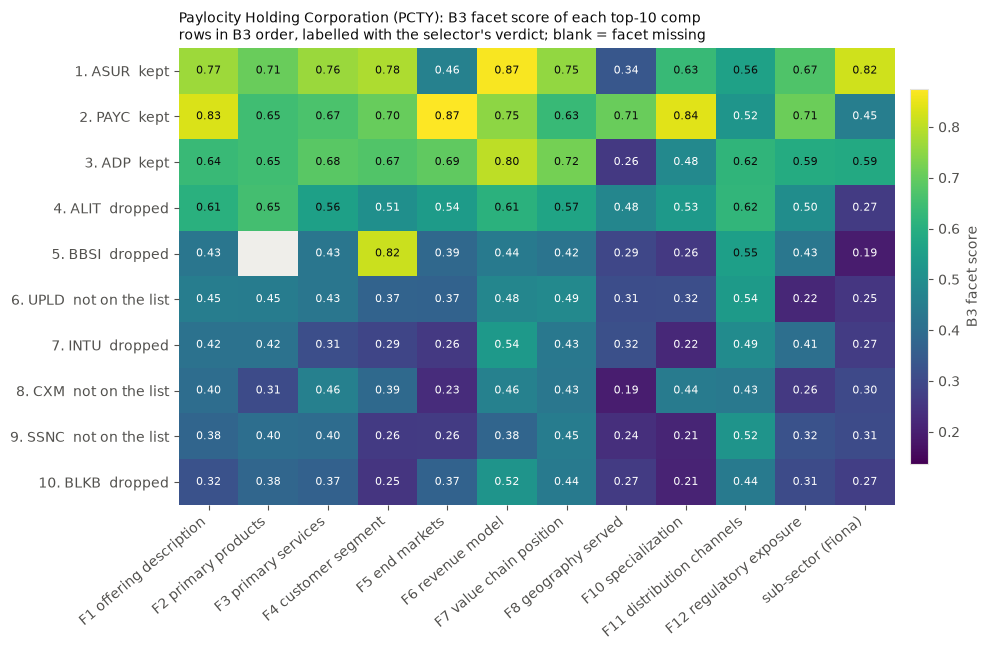

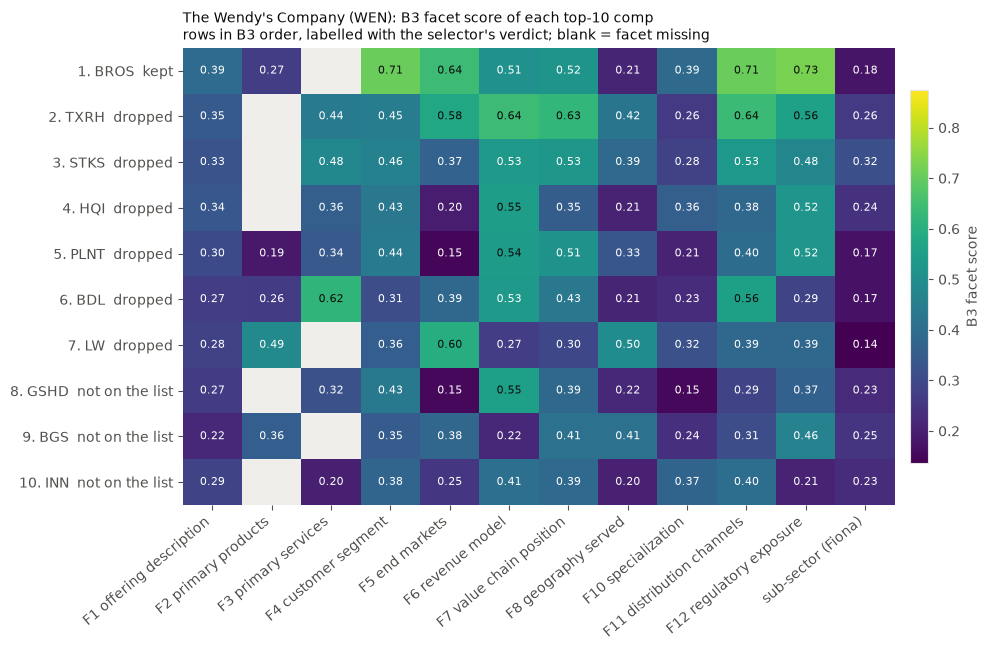

wrote outputs-local\v1a\04_selection\facet_contribution\20261119T035222Z


In [11]:
ramp = plt.get_cmap("viridis").copy()
ramp.set_bad("#efeeea")
verdict = {(t, c): s_ for t, c, s_ in zip(j["target"], j["comp"], j["score"])}
id_of = dict(zip(universe["target_ciq_ticker"], universe["IQ_COMPANY_ID"]))
mats = {t: pair_facets(top10[top10["target"] == id_of[t]].sort_values("rank")) for t in GOLDEN}
vmin = min(np.nanmin(m.to_numpy()) for m in mats.values())
vmax = max(np.nanmax(m.to_numpy()) for m in mats.values())
word = {1: "kept", 0: "dropped"}
for t in GOLDEN:
    rows = top10[top10["target"] == id_of[t]].sort_values("rank")
    M = mats[t].to_numpy()
    names = [f"{int(r)}. {info.loc[c, 'target_ciq_ticker']}  {word.get(verdict.get((id_of[t], c)), 'not on the list')}"
             for r, c in zip(rows["rank"], rows["comp"])]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(rows) + 2.4))
    im = ax.imshow(np.ma.masked_invalid(M), cmap=ramp, vmin=vmin, vmax=vmax, aspect="auto")
    for a in range(M.shape[0]):
        for b in range(M.shape[1]):
            if not np.isnan(M[a, b]):
                ax.text(b, a, f"{M[a, b]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if (M[a, b] - vmin) / (vmax - vmin) < 0.55 else INK)
    ax.set_xticks(range(len(FACETS)), [LABEL[n] for n in FACETS], rotation=40, ha="right")
    ax.set_yticks(range(len(rows)), names)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_title(f"{info.loc[id_of[t], 'target_company_name']} ({t}): B3 facet score of each top-10 comp\n"
                 f"rows in B3 order, labelled with the selector's verdict; blank = facet missing", loc="left", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="B3 facet score")
    fig.tight_layout()
    fig.savefig(FACET_OUT / f"facet_heatmap_{t}.png", dpi=150)
    plt.show()
print("wrote", FACET_OUT.relative_to(ROOT))


**Reading** (2,538 pairs, 373 targets, 507 kept).
- **Separation:** the combined B3 similarity ranks kept above dropped comps with an AUC of 0.90. Alone, primary
  products (0.83), offering description (0.83), Fiona's sub-sector and revenue model (0.81) and value chain position
  (0.80) separate best; customer segment (0.71), distribution channels (0.72) and end markets (0.75) less; geography
  (0.56) barely. v1 (Haiku judge on v0's cosines) had combined 0.87, offering description best at 0.83, geography 0.53.
- **Lift of the top 10:** regulatory exposure lifts the closest comps most (0.23, 2.6 sd), then primary services,
  end markets and primary products (about 0.20); sub-sector lifts 0.18 but the most in sd (2.6), since its baseline
  is low. Geography lifts least (0.10, 0.7 sd).
- **Against people's grades:** customers and end markets are among the weakest separators of the selector's keeps,
  but among the facets that go most with Barbara's peer grade (X-learner, `09_analysis` Methods B and C). The
  selector leans on products, offering description and sub-sector.


## 4. Checks

In [12]:
import cosine_then_llm as ctl, check_prompt_versions as cpv
checks.add("every target answered", j["target"].nunique() == 373, f"{j['target'].nunique()} targets")
a = set(zip(sel["target"], sel["comp"])); b = set(zip(j["target"], j["comp"]))
checks.add("every selected B3 pair answered exactly once", a == b and not j.duplicated(["target", "comp"]).any(), f"{len(j)} pairs")
checks.add("no answer issues", j["issues"].fillna("").eq("").all(), str(j["issues"].fillna("").ne("").sum()))
checks.add("prompt 2026-11-04a, Sonnet", j["prompt_version"].eq(ctl.PROMPT_VERSION).all() and j["model"].eq(cur["selection"]["model"]).all())
import contextlib, io
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    jt = cpv.check_judge(); dt = cpv.check_direct()
checks.add("v1 record: saved selector prompts rebuild (373/373)", jt[0] == jt[1] == 373, str(jt))
checks.add("v1 record: saved direct-pick prompts rebuild (373/373)", dt[0] == dt[1] == 373, str(dt))
checks.show()

6/6 checks pass


,check,result,detail
0,every target answered,pass,373 targets
1,every selected B3 pair answered exactly once,pass,2538 pairs
2,no answer issues,pass,0
3,"prompt 2026-11-04a, Sonnet",pass,
4,v1 record: saved selector prompts rebuild (373/373),pass,"(373, 373, 0)"
5,v1 record: saved direct-pick prompts rebuild (373/373),pass,"(373, 373, 0)"


## 5. History (v1)

- **v0 (10-25/27):** Haiku 5.5 screened v0's cosine z >= 2 lists (prompt `2026-10-25a`; `outputs-local/v1/judge/`),
  and Haiku picked comps directly from the pool (`outputs-local/v1/suggest/`). GPT-6.1 Sol graded pairs as the judge.
- **11-04 (Matthew, Richard):** Sonnet and Haiku selectors on the B3 list built from Haiku facets, reading Haiku
  facets (`model_selection_eval.py`, reproduced exactly in v1a). Both strict: about 21% (Sonnet) and 17% (Haiku) of
  pairs kept; the direct picks were where the model mattered.
- **11-05 (Eric):** the current list was built and its 373 prompts written as a dry run; no answers until 2026-11-18.
- **Kethan's pipeline (11-12, on his machine):** GPT-6.1 Sol as selector on his own Sol-filled B3 list.